    Лабораторная работа №01
    Прикладная статистика: Химический состав образцов керамики

В лабораторной работе использовался открытый датасет UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/583/chemical+composition+of+ceramic+samples  Открытый репозиторий представляет нам кассификацию образцов древней китайской керамики - Longquan celadon на основе их химического состава на основе энергодисперсионной рентгеновской флуоресценции. Для изучения сырья и технологии обжига они отобрали 40 типичных осколков, относящихся к четырем культурным эпохам. В таблице представлены процентные содрежания таких соединений как: Na2O, MgO, Al2O3, SiO2, K2O, CaO, TiO2, Fe2O3, MnO, CuO, ZnO, PbO2, Rb2O, SrO, Y2O3, ZrO2, P2O5. Их содержание представлено в основах(body) и в глазури(glaze) остатков. 

Цель исследования: провести статистический анализ химического состава образцов керамики Longquan celadon; исследовать особенности распредления компонентов в body и glaze;  сравнить процентное содержание вещест в body и glaze в рамках 1 осататка керамики. 

В рамках данной лабораторной работы мы будем подробно изучать 4 случайные величины: процентное содержание Na2O в body, процентное содержание Na2O в glaze, процентное содержание Al2O3 в body, процентное содержание Al2O3 в glaze. Параметры являются случайными величинами, так как их содержание можно узнать только на основе измерения - энергодисперсионной рентгеновской флуоресценции. Мы не можем знать заранее точное содержание изучаемых оксидов. А образец керамики мы выбиарем случайно. Поэтому мы можем изучать данные случайные величины прикладной математической статистикой.

In [6]:
import pandas as pd

df = pd.read_csv("Chemical Composion of Ceramic.csv")

df.head()


,Ceramic Name,Part,Na2O,MgO,Al2O3,SiO2,K2O,CaO,TiO2,Fe2O3,MnO,CuO,ZnO,PbO2,Rb2O,SrO,Y2O3,ZrO2,P2O5
0,FLQ-1-b,Body,0.62,0.38,19.61,71.99,4.84,0.31,0.07,1.18,630,10,70,10,430,0,40,80,90
1,FLQ-2-b,Body,0.57,0.47,21.19,70.09,4.98,0.49,0.09,1.12,380,20,80,40,430,-10,40,100,110
2,FLQ-3-b,Body,0.49,0.19,18.60,74.70,3.47,0.43,0.06,1.07,420,20,50,50,380,40,40,80,200
3,FLQ-4-b,Body,0.89,0.30,18.01,74.19,4.01,0.27,0.09,1.23,460,20,70,60,380,10,40,70,210
4,FLQ-5-b,Body,0.03,0.36,18.41,73.99,4.33,0.65,0.05,1.19,380,40,90,40,360,10,30,80,150


In [7]:
df.shape

(88, 19)

In [8]:
df["Part"].value_counts()

Part
Body     44
Glaze    44
Name: count, dtype: int64

In [9]:
df[["SiO2", "Al2O3", "CaO"]].describe()

,SiO2,Al2O3,CaO
count,88.000000,88.000000,88.000000
mean,69.825114,17.460909,4.171818
std,2.754377,4.703422,4.305801
min,63.880000,11.300000,0.120000
25%,67.737500,13.007500,0.180000
50%,69.990000,16.205000,2.690000
75%,71.840000,21.707500,7.912500
max,75.950000,26.480000,13.690000


In [10]:
df.groupby("Part")[["SiO2", "Al2O3", "CaO"]].mean()

,SiO2,Al2O3,CaO
Part,,,
Body,69.221818,21.812045,0.277273
Glaze,70.428409,13.109773,8.066364


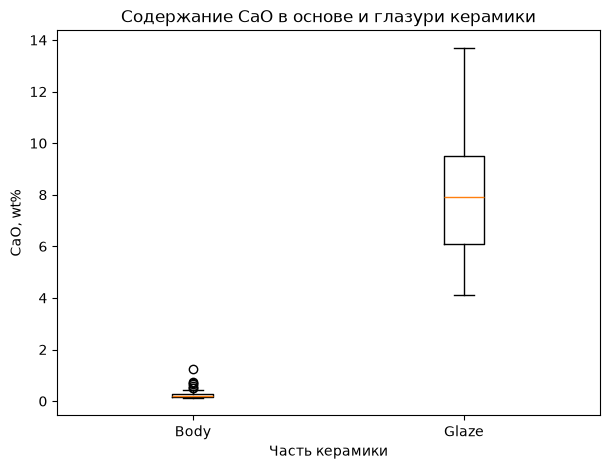

In [13]:
import matplotlib.pyplot as plt

body_cao = df[df["Part"] == "Body"]["CaO"]
glaze_cao = df[df["Part"] == "Glaze"]["CaO"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [body_cao, glaze_cao],
    tick_labels=["Body", "Glaze"]
)

plt.title("Содержание CaO в основе и глазури керамики")
plt.xlabel("Часть керамики")
plt.ylabel("CaO, wt%")

plt.show()
